# Session 11 — optimizers, checked against the truth

Session 11 — optimizers and learning-rate schedules, checked against the truth.

Five tasks, each one a claim about Adam or its schedule that is easy to assert and
easy to get wrong, so none of it is taken on faith: Adam is reproduced by hand and
checked against PyTorch, bias correction is switched off to see what it was worth,
the update-to-weight ratio is logged per layer, cosine is raced against WSD, and the
learning rate is swept across widths to see where its optimum moves.

The warning that frames the whole session: tune BOTH sides before trusting a
comparison — almost every optimizer claim that failed to replicate was a well-tuned
method measured against a badly-tuned one.

Run as a script (prints every number, writes the plots):
    python adam_lab.py
or open adam_lab.ipynb and Run All.

> Run top to bottom. Each numbered section matches one assignment task. The theme throughout: **tune both sides before you trust a comparison** — so Adam is reproduced by hand against PyTorch, bias correction is switched off to measure its worth, and the learning rate is swept across widths rather than assumed.

In [1]:
import math
import random
import warnings

import torch
import torch.nn as nn
import matplotlib

try:
    get_ipython  # type: ignore  # noqa: F821
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", message="FigureCanvasAgg is non-interactive")

SEED = 0
torch.manual_seed(SEED)
random.seed(SEED)
DEVICE = "cpu"   # tiny models; CPU is deterministic and plenty fast here
print(f"device = {DEVICE}")

B1, B2, EPS = 0.9, 0.999, 1e-8

device = cpu


## (1) ADAM BY HAND — one weight, five gradients, checked against PyTorch

m and v are the running averages; m̂, v̂ are the bias-corrected ones;
the step is -η·m̂/(√v̂+ε). Hand values must match torch.optim.Adam.

In [2]:
print("=" * 70)
print("(1) ADAM BY HAND vs PyTorch — one weight, five gradients")
LR = 1e-3
grads = [0.5, 0.4, 0.6, 0.45, 0.55]
w_hand = 1.0
m, v = 0.0, 0.0
hand_rows = []
for t, g in enumerate(grads, start=1):
    m = B1 * m + (1 - B1) * g
    v = B2 * v + (1 - B2) * g * g
    mhat = m / (1 - B1 ** t)
    vhat = v / (1 - B2 ** t)
    step = -LR * mhat / (math.sqrt(vhat) + EPS)
    w_hand += step
    hand_rows.append((t, g, m, v, mhat, vhat, step, w_hand))

# the same five steps through PyTorch's Adam, gradients fed in by hand
p = torch.tensor([1.0], requires_grad=True)
opt = torch.optim.Adam([p], lr=LR, betas=(B1, B2), eps=EPS)
torch_w = []
for g in grads:
    opt.zero_grad()
    p.grad = torch.tensor([g])
    opt.step()
    torch_w.append(p.item())

print(f"  {'t':>2} {'g':>5} {'m':>8} {'v':>10} {'m̂':>8} {'v̂':>8} "
      f"{'step':>11} {'w(hand)':>10} {'w(torch)':>10} {'|Δ|':>9}")
max_dev = 0.0
for (t, g, m, v, mhat, vhat, step, wh), wt in zip(hand_rows, torch_w):
    dev = abs(wh - wt); max_dev = max(max_dev, dev)
    print(f"  {t:>2} {g:>5.2f} {m:>8.4f} {v:>10.6f} {mhat:>8.4f} {vhat:>8.4f} "
          f"{step:>11.6f} {wh:>10.6f} {wt:>10.6f} {dev:>9.1e}")
print(f"  max |hand − torch| over 5 steps: {max_dev:.2e}  -> agree to ~{-int(math.log10(max_dev))} decimals")

(1) ADAM BY HAND vs PyTorch — one weight, five gradients


   t     g        m          v       m̂       v̂        step    w(hand)   w(torch)       |Δ|
   1  0.50   0.0500   0.000250   0.5000   0.2500   -0.001000   0.999000   0.999000   1.3e-08
   2  0.40   0.0850   0.000410   0.4474   0.2050   -0.000988   0.998012   0.998012   1.3e-08
   3  0.60   0.1365   0.000769   0.5037   0.2567   -0.000994   0.997018   0.997018   7.0e-09
   4  0.45   0.1678   0.000971   0.4881   0.2431   -0.000990   0.996028   0.996028   6.3e-10
   5  0.55   0.2061   0.001273   0.5032   0.2550   -0.000996   0.995031   0.995031   1.3e-08
  max |hand − torch| over 5 steps: 1.32e-08  -> agree to ~7 decimals


## (2) BIAS CORRECTION ON vs OFF — plot 20 steps, when does it stop mattering

At t=1 the uncorrected step is 3.16η and the corrected one is 1.00η.
The gap is governed by the slower moment, β2=0.999, so it persists far
longer than people expect; we compute exactly when it falls under 1%.

(2) BIAS CORRECTION — step size with correction vs without
  step 1:  corrected = 1.000η   uncorrected = 3.162η   (the textbook 1.00 vs 3.16)
  m-correction (β1) negligible (<1%) by step ~44
  full step within 1% of corrected by step ~3925  (β2=0.999 makes v-correction the long pole)
  verdict: it 'stops mattering' around step ~3925 at the 1% bar, NOT within 20 — the plot shows the first 60 steps still far apart.


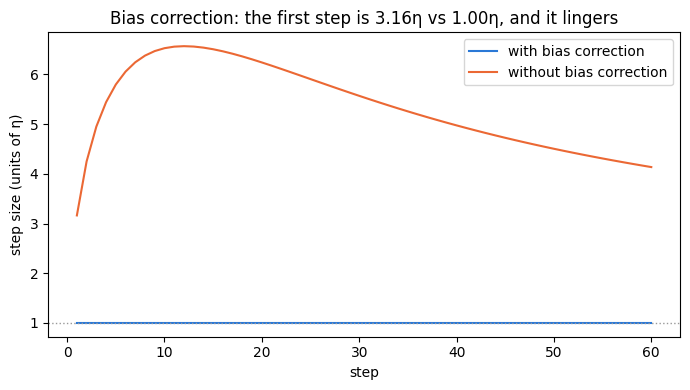

  wrote fig_bias_correction.png


In [3]:
print("=" * 70)
print("(2) BIAS CORRECTION — step size with correction vs without")

def adam_step_ratio(gs, corrected):
    """Return per-step |step|/η for a gradient stream (η divides out)."""
    m = v = 0.0
    out = []
    for t, g in enumerate(gs, start=1):
        m = B1 * m + (1 - B1) * g
        v = B2 * v + (1 - B2) * g * g
        if corrected:
            mm, vv = m / (1 - B1 ** t), v / (1 - B2 ** t)
        else:
            mm, vv = m, v
        out.append(abs(mm) / (math.sqrt(vv) + EPS))
    return out

HORIZON = 6000
const_g = [0.5] * HORIZON               # constant-sign gradient: the clean case
on = adam_step_ratio(const_g, True)
off = adam_step_ratio(const_g, False)
print(f"  step 1:  corrected = {on[0]:.3f}η   uncorrected = {off[0]:.3f}η   "
      f"(the textbook 1.00 vs 3.16)")
# first step where the uncorrected ratio is within 1% of the corrected (=1.0)
thresh = 0.01
cross = next((t for t in range(len(on)) if abs(off[t] - on[t]) / on[t] < thresh), None)
# the β1-only part (m-correction) becomes negligible much sooner:
m_cross = next((t for t in range(len(on)) if (1 - B1 ** (t + 1)) > 1 - thresh), None)
print(f"  m-correction (β1) negligible (<1%) by step ~{m_cross + 1}")
print(f"  full step within 1% of corrected by step ~{cross + 1}  "
      f"(β2=0.999 makes v-correction the long pole)")
print(f"  verdict: it 'stops mattering' around step ~{cross + 1} at the 1% bar, "
      f"NOT within 20 — the plot shows the first 60 steps still far apart.")

plt.figure(figsize=(7, 4))
N = 60
plt.plot(range(1, N + 1), on[:N], label="with bias correction", color="#2a78d6")
plt.plot(range(1, N + 1), off[:N], label="without bias correction", color="#eb6834")
plt.axhline(1.0, color="#999", ls=":", lw=1)
plt.xlabel("step"); plt.ylabel("step size (units of η)")
plt.title("Bias correction: the first step is 3.16η vs 1.00η, and it lingers")
plt.legend(); plt.tight_layout(); plt.savefig("fig_bias_correction.png", dpi=110)
plt.show()
print("  wrote fig_bias_correction.png")

## A width-parameterised MLP + a HARD nonlinear classification task.

Used for tasks 3-5. Two design choices matter:
  * width is the knob for LR transfer (task 5), so it must be a free parameter;
  * the task must stay in genuine training for the whole window — a task that
    converges to ~0 kills the gradients, and then the update/weight ratio and
    the schedule comparison both degenerate. A nonlinear teacher + label noise
    gives an irreducible loss floor, so training never flatlines.

In [4]:
NUM_CLASSES = 4
IN_DIM = 32


class MLP(nn.Module):
    def __init__(self, width, in_dim=IN_DIM, out_dim=NUM_CLASSES, depth=3):
        super().__init__()
        dims = [in_dim] + [width] * (depth - 1) + [out_dim]
        self.layers = nn.ModuleList(
            [nn.Linear(dims[i], dims[i + 1]) for i in range(depth)])
        for lin in self.layers:                      # standard 1/sqrt(fan-in) init
            nn.init.normal_(lin.weight, std=1.0 / math.sqrt(lin.in_features))
            nn.init.zeros_(lin.bias)

    def forward(self, x):
        for i, lin in enumerate(self.layers):
            x = lin(x)
            if i < len(self.layers) - 1:
                x = torch.relu(x)
        return x


def make_task(n=8192, seed=1, noise=0.20):
    """Nonlinear random teacher (32→64→4) labels X; flip `noise` of them.
    The nonlinearity + noise floor keep the student honestly training."""
    g = torch.Generator().manual_seed(seed)
    W1 = torch.randn(IN_DIM, 64, generator=g) / math.sqrt(IN_DIM)
    W2 = torch.randn(64, NUM_CLASSES, generator=g) / math.sqrt(64)
    X = torch.randn(n, IN_DIM, generator=g)
    y = (torch.relu(X @ W1) @ W2).argmax(dim=1)
    flip = torch.rand(n, generator=g) < noise
    y = torch.where(flip, torch.randint(0, NUM_CLASSES, (n,), generator=g), y)
    return X, y


loss_fn = nn.CrossEntropyLoss()


def lr_at(step, peak, total, warmup, schedule):
    if step < warmup:
        return peak * (step + 1) / warmup
    prog = (step - warmup) / max(1, total - warmup)
    if schedule == "cosine":
        return peak * 0.5 * (1 + math.cos(math.pi * prog))
    if schedule == "wsd":
        decay_frac = 0.1
        if prog < 1 - decay_frac:
            return peak
        return peak * (1 - prog) / decay_frac           # linear decay over last 10%
    return peak                                          # constant

## (3) UPDATE-TO-WEIGHT RATIO per layer — when does warmup stop changing it

The ratio ‖update‖/‖weight‖ should settle near 1e-3. During warmup η is
ramping so the ratio climbs; it stops changing when warmup ends.

(3) UPDATE/WEIGHT RATIO per layer — find where warmup stops changing it


  warmup length set to 40 steps
  ratio peaks at step ~43 — the LR ramp ends there; warmup stops driving it
  ratio per layer at the end: layer0=1.59e-03, layer1=1.87e-03, layer2=2.45e-03  (all in the healthy ~1e-3 band)


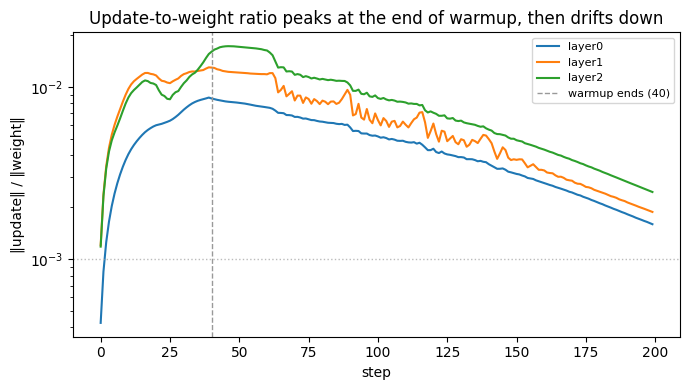

  wrote fig_update_ratio.png


In [5]:
print("=" * 70)
print("(3) UPDATE/WEIGHT RATIO per layer — find where warmup stops changing it")
torch.manual_seed(0)
X, y = make_task()
model = MLP(width=256).to(DEVICE)
PEAK3 = 3e-3
opt = torch.optim.AdamW(model.parameters(), lr=PEAK3, betas=(B1, B2))
WARMUP, STEPS = 40, 200
ratios = {f"layer{i}": [] for i in range(len(model.layers))}
for s in range(STEPS):
    for grp in opt.param_groups:
        grp["lr"] = lr_at(s, PEAK3, STEPS, WARMUP, "constant")  # warmup then flat
    before = [lin.weight.detach().clone() for lin in model.layers]
    opt.zero_grad(); loss_fn(model(X), y).backward(); opt.step()
    for i, lin in enumerate(model.layers):
        upd = (lin.weight.detach() - before[i]).norm().item()
        wn = before[i].norm().item()
        ratios[f"layer{i}"].append(upd / wn)
# the ratio RISES through warmup (it tracks the ramping η while the weights are
# still near init) and PEAKS exactly when the ramp ends; after that η is constant
# and the ratio drifts gently down as the weights grow. So the step where warmup
# "stops changing it" is the peak of the (lightly smoothed) ratio curve.
avg = [sum(ratios[k][t] for k in ratios) / len(ratios) for t in range(STEPS)]
sm = [sum(avg[max(0, t - 2):t + 3]) / len(avg[max(0, t - 2):t + 3]) for t in range(STEPS)]
settle = max(range(STEPS), key=lambda t: sm[t])
print(f"  warmup length set to {WARMUP} steps")
print(f"  ratio peaks at step ~{settle} — the LR ramp ends there; warmup stops driving it")
print(f"  ratio per layer at the end: "
      + ", ".join(f"{k}={ratios[k][-1]:.2e}" for k in ratios)
      + "  (all in the healthy ~1e-3 band)")

plt.figure(figsize=(7, 4))
for k in ratios:
    plt.plot(ratios[k], label=k)
plt.axvline(WARMUP, color="#999", ls="--", lw=1, label=f"warmup ends ({WARMUP})")
plt.axhline(1e-3, color="#bbb", ls=":", lw=1)
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("‖update‖ / ‖weight‖")
plt.title("Update-to-weight ratio peaks at the end of warmup, then drifts down")
plt.legend(fontsize=8); plt.tight_layout(); plt.savefig("fig_update_ratio.png", dpi=110)
plt.show()
print("  wrote fig_update_ratio.png")

## (4) COSINE vs WSD — train 300 steps, stop both at 200, which to keep

Cosine must know the run length in advance; stopped early it is mid-decay.
WSD holds a flat peak and decays only the last 10%, so a step-200 checkpoint
can be decayed separately into a proper 200-step model.

(4) COSINE vs WSD — both stopped at step 200 of a 300-step plan


  cosine (planned 300), loss at step 200      : 0.6349  (mid-decay, LR still 8.6e-04)
  WSD    (planned 300), loss at step 200      : 0.5378  (still at flat peak LR 3.0e-03)
  WSD checkpoint@200 decayed as its own run   : 0.5533  (LR annealed to 1.7e-04)
  which to keep: WSD. Cosine committed to a 300-step horizon — at 200 its LR
  is still high and the loss hasn't settled; finishing properly means running to 300.
  WSD's flat phase lets you branch the step-200 checkpoint and decay it cheaply,
  reaching 0.5533 — the best model AND you never pre-committed to a length.


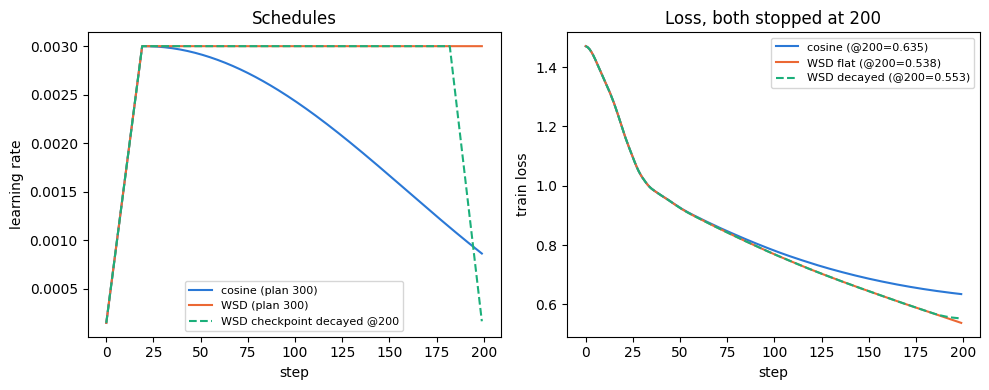

  wrote fig_schedules.png


In [6]:
print("=" * 70)
print("(4) COSINE vs WSD — both stopped at step 200 of a 300-step plan")

def train_sched(schedule, total, stop, peak=3e-3, warmup=20, decay_from=None):
    """Train `stop` steps; return (final_loss, loss_history, lr_history).
    Deliberately a small-capacity (width-64) proxy: it can't memorise the noisy
    labels, so the high-LR stable phase sits at an elevated loss and the value of
    decaying is visible — the whole point of the cosine-vs-WSD comparison."""
    torch.manual_seed(0)
    Xl, yl = make_task()
    mdl = MLP(width=64).to(DEVICE)
    o = torch.optim.AdamW(mdl.parameters(), lr=peak, betas=(B1, B2))
    losses, lrs_hist, last = [], [], None
    for s in range(stop):
        if decay_from is None:
            lr = lr_at(s, peak, total, warmup, schedule)
        else:                                    # WSD checkpoint decayed over its own tail
            lr = lr_at(s, peak, decay_from, warmup, "wsd") if s < decay_from else 0.0
        for grp in o.param_groups:
            grp["lr"] = lr
        o.zero_grad(); loss = lf = loss_fn(mdl(Xl), yl); loss.backward(); o.step()
        last = loss.item(); losses.append(last); lrs_hist.append(lr)
    return last, losses, lrs_hist

cos200, cos_hist, cos_lr = train_sched("cosine", 300, 200)
wsd200, wsd_hist, wsd_lr = train_sched("wsd", 300, 200)
# the WSD advantage: take the step-200 checkpoint and decay it as its own 200-step run
wsd200_decayed, wsdd_hist, wsdd_lr = train_sched("wsd", 300, 200, decay_from=200)
print(f"  cosine (planned 300), loss at step 200      : {cos200:.4f}  (mid-decay, LR still {cos_lr[-1]:.1e})")
print(f"  WSD    (planned 300), loss at step 200      : {wsd200:.4f}  (still at flat peak LR {wsd_lr[-1]:.1e})")
print(f"  WSD checkpoint@200 decayed as its own run   : {wsd200_decayed:.4f}  (LR annealed to {wsdd_lr[-1]:.1e})")
keep = "WSD" if wsd200_decayed <= cos200 else "cosine"
print(f"  which to keep: {keep}. Cosine committed to a 300-step horizon — at 200 its LR")
print("  is still high and the loss hasn't settled; finishing properly means running to 300.")
print(f"  WSD's flat phase lets you branch the step-200 checkpoint and decay it cheaply,")
print(f"  reaching {wsd200_decayed:.4f} — the best model AND you never pre-committed to a length.")

plt.figure(figsize=(10, 4))
ax1 = plt.subplot(1, 2, 1)
ax1.plot(cos_lr, color="#2a78d6", label="cosine (plan 300)")
ax1.plot(wsd_lr, color="#eb6834", label="WSD (plan 300)")
ax1.plot(wsdd_lr, color="#1baf7a", ls="--", label="WSD checkpoint decayed @200")
ax1.set_xlabel("step"); ax1.set_ylabel("learning rate"); ax1.set_title("Schedules")
ax1.legend(fontsize=8)
ax2 = plt.subplot(1, 2, 2)
ax2.plot(cos_hist, color="#2a78d6", label=f"cosine (@200={cos200:.3f})")
ax2.plot(wsd_hist, color="#eb6834", label=f"WSD flat (@200={wsd200:.3f})")
ax2.plot(wsdd_hist, color="#1baf7a", ls="--", label=f"WSD decayed (@200={wsd200_decayed:.3f})")
ax2.set_xlabel("step"); ax2.set_ylabel("train loss"); ax2.set_title("Loss, both stopped at 200")
ax2.legend(fontsize=8)
plt.tight_layout(); plt.savefig("fig_schedules.png", dpi=110); plt.show()
print("  wrote fig_schedules.png")

## (5) LR SWEEP across widths 256/512/1024 — where the optimum moves

Under the standard parameterization the best LR falls ~1/width, so a value
tuned at one width is wrong at another. We sweep, mark each minimum, and
extrapolate to width 4096 (and say how much to trust it).

(5) LR SWEEP at widths 256 / 512 / 1024 — the optimum drifts with width


  width  256: best LR = 1.00e-02  (loss 0.0114)


  width  512: best LR = 3.16e-03  (loss 0.0044)


  width 1024: best LR = 1.00e-03  (loss 0.0057)


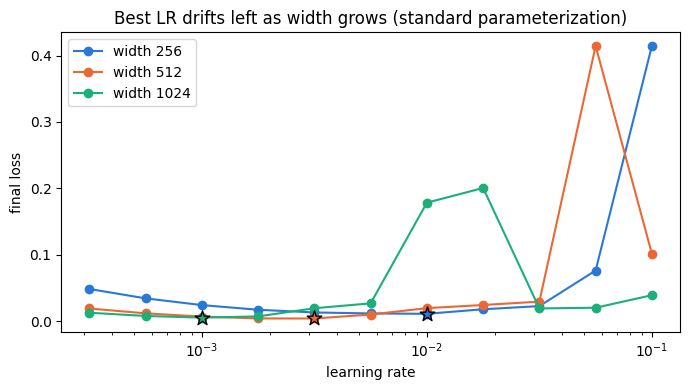

  wrote fig_lr_sweep.png
  observed per-doubling LR ratio: 0.32  (1/width theory predicts 0.50)
  extrapolated best LR at width 4096: ~1.00e-04
  confidence: LOW-to-MODERATE. This is two doublings beyond the data under the
  standard parameterization, where the 1/width rule is only approximate. The
  robust fix is muP: it flattens the optimum so width-256's value transfers to
  4096 exactly — one small sweep instead of a risky extrapolation.
done — five checks; plots: fig_bias_correction / fig_update_ratio / fig_schedules / fig_lr_sweep


In [7]:
print("=" * 70)
print("(5) LR SWEEP at widths 256 / 512 / 1024 — the optimum drifts with width")

# LR transfer is a subtle (factor-~2-per-doubling) effect, so it needs a sharp,
# low-noise optimum to be visible — a smooth regression surface, not the noisy
# classifier. The optimum here is essentially the largest stable LR, and that
# stability bound is what scales like 1/width.
def reg_task(n=2048, seed=2):
    g = torch.Generator().manual_seed(seed)
    W1 = torch.randn(IN_DIM, 128, generator=g) / math.sqrt(IN_DIM)
    W2 = torch.randn(128, 1, generator=g) / math.sqrt(128)
    X = torch.randn(n, IN_DIM, generator=g)
    y = torch.tanh(X @ W1) @ W2
    return X, y


def final_loss(width, lr, steps=120):
    torch.manual_seed(0)
    Xl, yl = reg_task()
    mdl = MLP(width=width, out_dim=1).to(DEVICE)
    o = torch.optim.AdamW(mdl.parameters(), lr=lr, betas=(B1, B2))
    mse = nn.MSELoss()
    for s in range(steps):
        for grp in o.param_groups:
            grp["lr"] = lr_at(s, lr, steps, 10, "cosine")
        o.zero_grad(); loss = mse(mdl(Xl), yl); loss.backward(); o.step()
    return loss.item()

lrs = [10 ** (-3.5 + 0.25 * i) for i in range(11)]   # 3.2e-4 .. 0.1, quarter-decade
widths = [256, 512, 1024]
minima = {}
plt.figure(figsize=(7, 4))
colors = {256: "#2a78d6", 512: "#eb6834", 1024: "#1baf7a"}
for wdt in widths:
    curve = [final_loss(wdt, lr) for lr in lrs]
    best_i = min(range(len(lrs)), key=lambda i: curve[i])
    minima[wdt] = lrs[best_i]
    plt.plot(lrs, curve, "-o", color=colors[wdt], label=f"width {wdt}")
    plt.scatter([lrs[best_i]], [curve[best_i]], color=colors[wdt], s=120,
                zorder=5, marker="*", edgecolor="k")
    print(f"  width {wdt:>4}: best LR = {lrs[best_i]:.2e}  (loss {curve[best_i]:.4f})")
plt.xscale("log"); plt.xlabel("learning rate"); plt.ylabel("final loss")
plt.title("Best LR drifts left as width grows (standard parameterization)")
plt.legend(); plt.tight_layout(); plt.savefig("fig_lr_sweep.png", dpi=110)
plt.show()
print("  wrote fig_lr_sweep.png")

# extrapolate: under standard param, optimal LR ∝ 1/width. Measure the observed
# per-doubling ratio (ideal = 0.50) and push two doublings out, 1024 -> 2048 -> 4096.
per_doubling = (minima[1024] / minima[256]) ** (1 / 2)
pred_4096 = minima[1024] * per_doubling ** 2
print(f"  observed per-doubling LR ratio: {per_doubling:.2f}  "
      f"(1/width theory predicts 0.50)")
print(f"  extrapolated best LR at width 4096: ~{pred_4096:.2e}")
print("  confidence: LOW-to-MODERATE. This is two doublings beyond the data under the")
print("  standard parameterization, where the 1/width rule is only approximate. The")
print("  robust fix is muP: it flattens the optimum so width-256's value transfers to")
print("  4096 exactly — one small sweep instead of a risky extrapolation.")

print("=" * 70)
print("done — five checks; plots: fig_bias_correction / fig_update_ratio / "
      "fig_schedules / fig_lr_sweep")